# Delivery Promise Lab | From historical delay data to a pilot decision

**Distinct portfolio extension** to the original Olist analysis. This notebook intentionally begins from *published regional aggregate data*, not raw orders. See `NOTICE.md` for attribution.

**Decision question:** If an operations team can intervene on only a fraction of shipments, which states should enter a first pilot? What cost/value assumptions would justify one?

**Do not interpret the simulation as measured causal impact.** The source covers 2017–2018 and contains no actual intervention outcomes or verified cost-per-late-delivery figures.

## 1 — Load and validate decision data

Reconcile the published state export against nationwide totals. The source CSV omits states with small order volumes, a source of easy but consequential denominator mistakes.

In [1]:
from src.promise_lab import load_state_data, Assumptions, allocate, scenarios
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
model = load_state_data()
print('Coverage:', model['coverage'])
assert model['coverage']['excluded_delivered'] == 849
assert model['coverage']['excluded_late'] == 48
states = pd.DataFrame(model['rows'])
states.head(8)[['state','delivered_orders','late_orders','observed_late_rate','risk_adjusted_rate','above_national_wilson']]

Coverage: {'states_in_export': 21, 'delivered_in_export': 95354, 'late_in_export': 6483, 'delivered_national': 96203, 'late_national': 6531, 'excluded_delivered': 849, 'excluded_late': 48, 'coverage_rate': 0.9911749113852998, 'note': 'Original state_logistics export contains only states meeting its minimum-volume filter; excluded states are NOT treated as zero risk.'}


,state,delivered_orders,late_orders,observed_late_rate,risk_adjusted_rate,above_national_wilson
0,AL,396,85,0.214646,0.165399,True
1,MA,713,125,0.175316,0.151783,True
2,CE,1273,176,0.138256,0.128702,True
3,SE,332,51,0.153614,0.121386,True
4,RJ,12310,1495,0.121446,0.120590,True
5,BA,3253,396,0.121734,0.118615,True
6,PI,475,66,0.138947,0.117893,True
7,PA,942,106,0.112527,0.104709,True


## 2 — Compare both risk *rate* and absolute *volume*

Raw percentages make small states look extreme; late-order totals can make large states look worse simply because they ship more. Use both, add a 95% Wilson interval, and shrink sparse proportions toward a national prior. The prior strength of 200 is a planning choice; do not describe the resulting rate as ground truth.

,state,delivered_orders,late_orders,observed_late_rate,wilson_95_low,wilson_95_high
19,SP,40399,1817,0.044976,0.042998,0.047041
4,RJ,12310,1495,0.121446,0.115794,0.127335
18,MG,11319,519,0.045852,0.042150,0.049862
5,BA,3253,396,0.121734,0.110941,0.133419
16,RS,5327,325,0.061010,0.054893,0.067759
13,SC,3537,291,0.082273,0.073664,0.091788
8,ES,1992,214,0.107430,0.094579,0.121792
20,PR,4903,199,0.040587,0.035414,0.046480
2,CE,1273,176,0.138256,0.120381,0.158308
10,PE,1587,153,0.096408,0.082847,0.111919


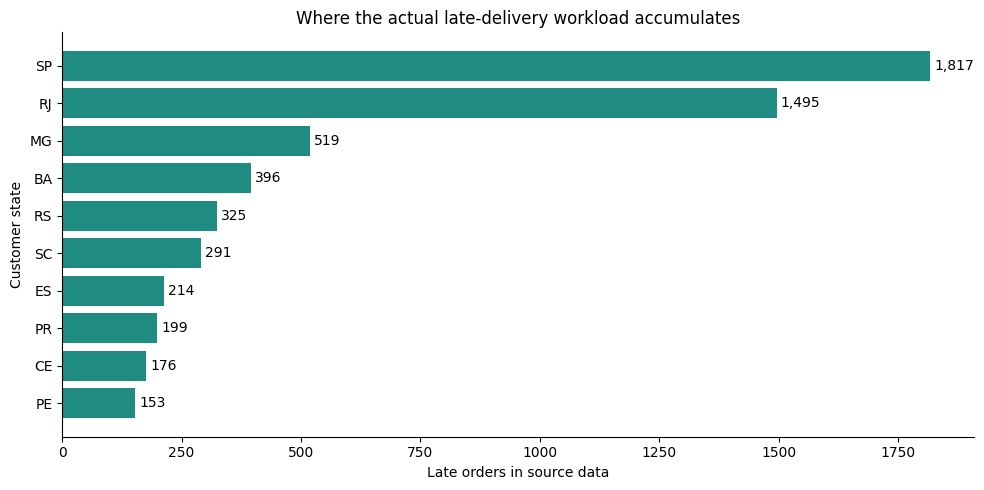

In [2]:
display(states.sort_values('late_orders', ascending=False).head(10)[['state','delivered_orders','late_orders','observed_late_rate','wilson_95_low','wilson_95_high']])
fig,ax=plt.subplots(figsize=(10,5))
top=states.sort_values('late_orders',ascending=False).head(10).sort_values('late_orders')
ax.barh(top.state,top.late_orders,color='#208b81')
ax.set(title='Where the actual late-delivery workload accumulates',xlabel='Late orders in source data',ylabel='Customer state')
for i,v in enumerate(top.late_orders):ax.text(v+8,i,f'{v:,.0f}',va='center')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout();plt.show()

## 3 — Allocate a limited hypothetical pilot

The priority rule is **expected prevented late orders per unit cost**, given the same per-order intervention cost across states. Each state has a hypothetical maximum coverage. Assumed efficacy (relative late-rate reduction) and modeled value per avoided late case are not available in the dataset.

In [3]:
base = Assumptions(budget_brl=15_000, cost_per_treated_order_brl=5, relative_late_reduction=.25, value_per_avoided_late_brl=150, max_state_coverage=.35)
plan=allocate(model,base)
print('Base-case scenario summary:', plan['summary'])
display(pd.DataFrame(plan['allocations']).query('treated_orders > 0')[['state','treated_orders','risk_adjusted_rate','modeled_late_avoided','modeled_cost_brl']])

Base-case scenario summary: {'treated_orders': 3000, 'modeled_late_avoided': 94.85551435322073, 'modeled_program_cost_brl': 15000, 'modeled_benefit_brl': 14228.327152983109, 'modeled_net_brl': -771.672847016891, 'break_even_value_per_avoided_late_brl': 158.1352449805222, 'unused_budget_brl': 0}


,state,treated_orders,risk_adjusted_rate,modeled_late_avoided,modeled_cost_brl
0,AL,138,0.165399,5.706250,690
1,MA,249,0.151783,9.448469,1245
2,CE,445,0.128702,14.318059,2225
3,SE,116,0.121386,3.520204,580
4,RJ,2052,0.120590,61.862532,10260


## 4 — Stress-test assumptions, never cherry-pick the most profitable outcome

Base case is deliberately allowed to be unprofitable. The break-even value is a decision threshold for *future validation*, not a claim of verified cost savings.

,scenario,efficacy,value_per_avoided_late_brl,modeled_late_avoided,modeled_program_cost_brl,modeled_net_brl
0,Conservative,0.10,75.0,37.942206,15000,-12154.334569
1,Base case,0.25,150.0,94.855514,15000,-771.672847
2,Optimistic,0.40,225.0,151.768823,15000,19147.985167


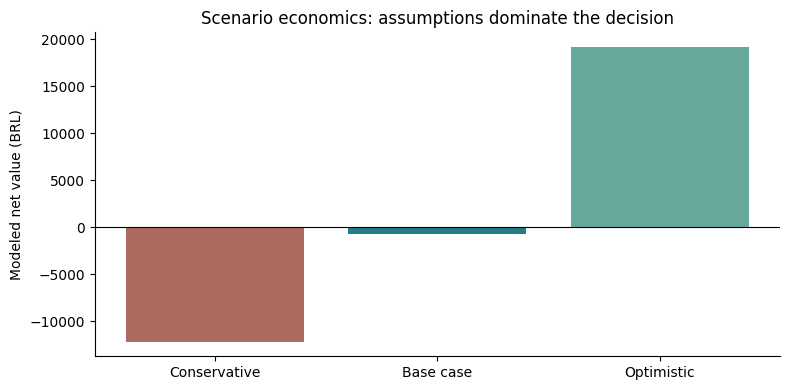

In [4]:
sensitivity=pd.DataFrame(scenarios(model,base))
display(sensitivity[['scenario','efficacy','value_per_avoided_late_brl','modeled_late_avoided','modeled_program_cost_brl','modeled_net_brl']])
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(sensitivity['scenario'],sensitivity['modeled_net_brl'],color=['#ad6a5e','#217e86','#67a99d'])
ax.axhline(0,color='black',linewidth=.8)
ax.set(ylabel='Modeled net value (BRL)',title='Scenario economics: assumptions dominate the decision')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout();plt.show()

## 5 — Recommendation, experiment design and limits

**Recommendation:** Do *not* sign off on national rollout from this dataset. Start with a narrowly controlled pilot, validate treatment cost and actual efficacy, and then reallocate using observed uplift.

**Candidate pilot markets:** RJ provides substantial late-order volume; AL and MA offer higher observed percentages but fewer orders. Because the model uses a uniform treatment cost, it ranks by adjusted risk. If local carrier costs differ, replace this ranking with incremental preventable delays per BRL.

**Experiment design:** Randomly allocate eligible shipments (within market and time strata) to a revised delivery-promise intervention versus business-as-usual. Pre-register late-delivery rate as primary outcome; monitor complaint rate, review score, net margin, and guardrails. Use intention-to-treat analysis and track both absolute and relative risk reductions.

**Key limitations:** (i) state aggregation hides route/carrier heterogeneity, (ii) 2017–18 is not representative of current operations, (iii) historical review differences are associational, (iv) costs, efficacy and monetary value are assumptions, (v) the source's state export excludes 849 national deliveries. See `docs/portfolio/decision_memo.md`.